# Base (soil disabled) precipitation threshold sensitivity: +1.2°C, +1.0°C, and +0.7°C

PPSA, TRAM, and HEEN, with `hrrrak_lapserate` and `met_hrrrak_lapserate`. The control is the existing **base** experiment with a 274.35 K (+1.2°C) air-temperature threshold. The **base_thresh07** experiment uses `PRECSPLITTING`, `TYPE = THRESH`, and `SNOW = 273.85 K` (+0.7°C). The soil model remains disabled (`SNP_SOIL = false`, `SOIL_FLUX = false`), with the original zero-layer initial profiles, `GEO_HEAT = 0.06`, constant ground-temperature generator, forcing, snow physics, filters, and output frequency. Only the precipitation cutoff and output experiment label change in effect.

The **base_thresh10** experiment uses the same setup with `SNOW = 274.15 K` (+1.0°C). The existing filename is retained so this notebook continues the base_thresh07 analysis.

Lowering the threshold changes precipitation near freezing from snow to rain. This is an air-temperature threshold sensitivity experiment. Existing controls and source inputs are preserved, with checksums recorded in each model site's `base_thresh07_runs.json`.

The comparison uses **WY2023, WY2024, and WY2025 for PPSA/TRAM**, and **WY2020, WY2021, and WY2022 for HEEN**, for both forcing variants. Earlier PPSA/TRAM simulations are retained on disk but excluded from these plots and statistics. At each site, all six simulation curves use the same available comparison window. The existing PPSA/TRAM runs end on September 1, 2025, so WY2025 is partial; HEEN's shared window ends September 30, 2022 at 05:00. First-season initialization flags refer to the original simulation start, not the first displayed year. All comparisons use identical shared hourly indices; no missing values are filled with zero. Figures display inline without automatic PNG/PDF exports.
The +1.2°C control keeps its existing on-disk name `base`; labels identify it as base +1.2°C. Both sets of six sensitivity simulations are included. The TRAM sensitivity runs use the version-specific empty-column vapor-transport guard documented below.

For PPSA/TRAM HRRR-only, the new run starts at the initial profile date (2019-10-01 06:00 UTC); the control’s extra 05:00 initialization record is excluded from pairing. This is outside the displayed WY2023–WY2025 window.

## Figure settings

Edit each simulation’s color, linewidth, and linestyle below. Solid lines show +1.2°C, dotted lines +1.0°C, and dashed lines +0.7°C. Blue is HRRR-AK, green is Met Mixed, and black is observed snow depth. `ANALYSIS_YEARS` limits figures and statistics.

In [1]:
ANALYSIS_YEARS = {'ppsa': (2023,2024,2025), 'tram': (2023,2024,2025), 'heen': (2020,2021,2022)}
FORCING_LABELS = {'hrrrak_lapserate':'HRRR-AK', 'met_hrrrak_lapserate':'Met Mixed'}
SITE_TITLES = {'ppsa':'Powder Patch (PPSA)', 'tram':'Mount Roberts Tramway (TRAM)', 'heen':'Heen Latinee (HEEN)'}
SIMULATION_STYLES = {
    ('hrrrak_lapserate','base'): {
        'label':'HRRR-AK base +1.2C', 'color':'tab:blue', 'linewidth':2.0, 'linestyle':'-'},
    ('hrrrak_lapserate','base_thresh10'): {
        'label':'HRRR-AK base +1.0C', 'color':'tab:blue', 'linewidth':2.0, 'linestyle':':' },
    ('hrrrak_lapserate','base_thresh07'): {
        'label':'HRRR-AK base +0.7C', 'color':'tab:blue', 'linewidth':2.0, 'linestyle':'--'},
    ('met_hrrrak_lapserate','base'): {
        'label':'Met Mixed base +1.2C', 'color':'tab:green', 'linewidth':2.0, 'linestyle':'-'},
    ('met_hrrrak_lapserate','base_thresh10'): {
        'label':'Met Mixed base +1.0C', 'color':'tab:green', 'linewidth':2.0, 'linestyle':':' },
    ('met_hrrrak_lapserate','base_thresh07'): {
        'label':'Met Mixed base +0.7C', 'color':'tab:green', 'linewidth':2.0, 'linestyle':'--'},
}
OBSERVATION_STYLE = {'color':'black', 'linewidth':1.25, 'alpha':.8}
MATCH_Y_AXES = True

CANDIDATES = ('base_thresh10','base_thresh07')
THRESHOLD_LABELS = {'base':'1.2°C', 'base_thresh10':'1.0°C', 'base_thresh07':'0.7°C'}

In [2]:
from pathlib import Path
import sys, importlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
    if (p/'sites/all_sites/_base_threshold_sensitivity.py').is_file()),None)
if ROOT is None: raise RuntimeError('Run from inside snow_modeling_point')
sys.path.insert(0,str(ROOT/'sites/all_sites'))
import _base_threshold_sensitivity as sensitivity
importlib.reload(sensitivity)
plt.rcParams.update({'font.size':12,'axes.labelsize':13,'axes.titlesize':14,
                     'legend.fontsize':11,'axes.spines.top':False,'axes.spines.right':False})
MODEL_ROOT=sensitivity.MODEL_ROOT
manifest=[row for experiment in CANDIDATES for site in sensitivity.PERIODS
    for row in json.loads((MODEL_ROOT/site/f'{experiment}_runs.json').read_text())]
missing=[row['output'] for row in manifest if not Path(row['output']).is_file()]
if missing: raise FileNotFoundError('Missing sensitivity outputs: '+', '.join(missing))
all_pairs={};audit_frames=[]
for experiment in CANDIDATES:
    candidate_pairs,audit=sensitivity.load_pairs(experiment=experiment)
    audit_frames.append(audit.assign(experiment=experiment))
    for key,frame in candidate_pairs.items():
        if key not in all_pairs:
            all_pairs[key]=frame.filter(regex='_base$').copy()
        if not all_pairs[key].index.equals(frame.index):
            raise ValueError(f'All three thresholds must have identical hourly coverage: {key}')
        columns=[c for c in frame if c.endswith('_'+experiment)]
        all_pairs[key]=all_pairs[key].join(frame[columns])
        for variable in ['HS_cm','SWE_mm','snowfall_mm','rainfall_mm']:
            all_pairs[key][f'delta_{variable}_{experiment}']=frame[f'delta_{variable}']
source_coverage=pd.concat(audit_frames,ignore_index=True)
# Preserve initialization flags from the actual run starts before selecting years.
first_water_years = {key:int(frame.index[0].year+(frame.index[0].month>=10)) for key,frame in all_pairs.items()}
pairs={};plot_windows={};comparison_rows=[]
for site,years in ANALYSIS_YEARS.items():
    requested_start=pd.Timestamp(min(years)-1,10,1)
    requested_end=pd.Timestamp(max(years),10,1)-pd.Timedelta(hours=1)
    frames=[all_pairs[(site,forcing)] for forcing in sensitivity.FORCINGS]
    start=max(requested_start,max(frame.index.min() for frame in frames))
    end=min(requested_end,min(frame.index.max() for frame in frames))
    if end<start: raise ValueError(f'No common comparison period for {site}')
    plot_windows[site]=(start,end)
    for forcing in sensitivity.FORCINGS:
        frame=all_pairs[(site,forcing)].loc[start:end]
        water_year=frame.index.year+(frame.index.month>=10).astype(int)
        pairs[(site,forcing)]=frame.loc[np.isin(water_year,years)].copy()
        comparison_rows.append(dict(site=site,forcing=forcing,water_years=', '.join(map(str,years)),
            start_UTC=start,end_UTC=end,hours=len(pairs[(site,forcing)])))
metric_frames=[]
for experiment in CANDIDATES:
    candidate_pairs={key:frame.rename(columns={f'delta_{v}_{experiment}':f'delta_{v}'
        for v in ['HS_cm','SWE_mm','snowfall_mm','rainfall_mm']}) for key,frame in pairs.items()}
    result,observations=sensitivity.seasonal_summary(candidate_pairs,
        first_water_years=first_water_years,candidate=experiment)
    result=result.rename(columns={c:c.replace(experiment,'candidate') for c in result if experiment in c})
    metric_frames.append(result.assign(experiment=experiment,threshold=THRESHOLD_LABELS[experiment]))
metrics=pd.concat(metric_frames,ignore_index=True)
comparison_coverage=pd.DataFrame(comparison_rows)
coverage_display=comparison_coverage.assign(forcing=comparison_coverage.forcing.map(FORCING_LABELS))
display(coverage_display.style.format({'start_UTC':lambda t:t.strftime('%d %b %Y %H:%M'),
    'end_UTC':lambda t:t.strftime('%d %b %Y %H:%M')}).hide(axis='index'))

site,forcing,water_years,start_UTC,end_UTC,hours
ppsa,HRRR-AK,"2023, 2024, 2025",01 Oct 2022 00:00,01 Sep 2025 00:00,25585
ppsa,Met Mixed,"2023, 2024, 2025",01 Oct 2022 00:00,01 Sep 2025 00:00,25585
tram,HRRR-AK,"2023, 2024, 2025",01 Oct 2022 06:00,01 Sep 2025 00:00,25579
tram,Met Mixed,"2023, 2024, 2025",01 Oct 2022 06:00,01 Sep 2025 00:00,25579
heen,HRRR-AK,"2020, 2021, 2022",01 Oct 2019 06:00,30 Sep 2022 05:00,26280
heen,Met Mixed,"2020, 2021, 2022",01 Oct 2019 06:00,30 Sep 2022 05:00,26280


## Main results: base +1.2°C, +1.0°C, and +0.7°C

Each site shows six hourly simulation curves and observations over the same comparison window. PPSA/TRAM use WY2023–WY2025 and HEEN uses WY2020–WY2022. Partial years are retained and flagged.

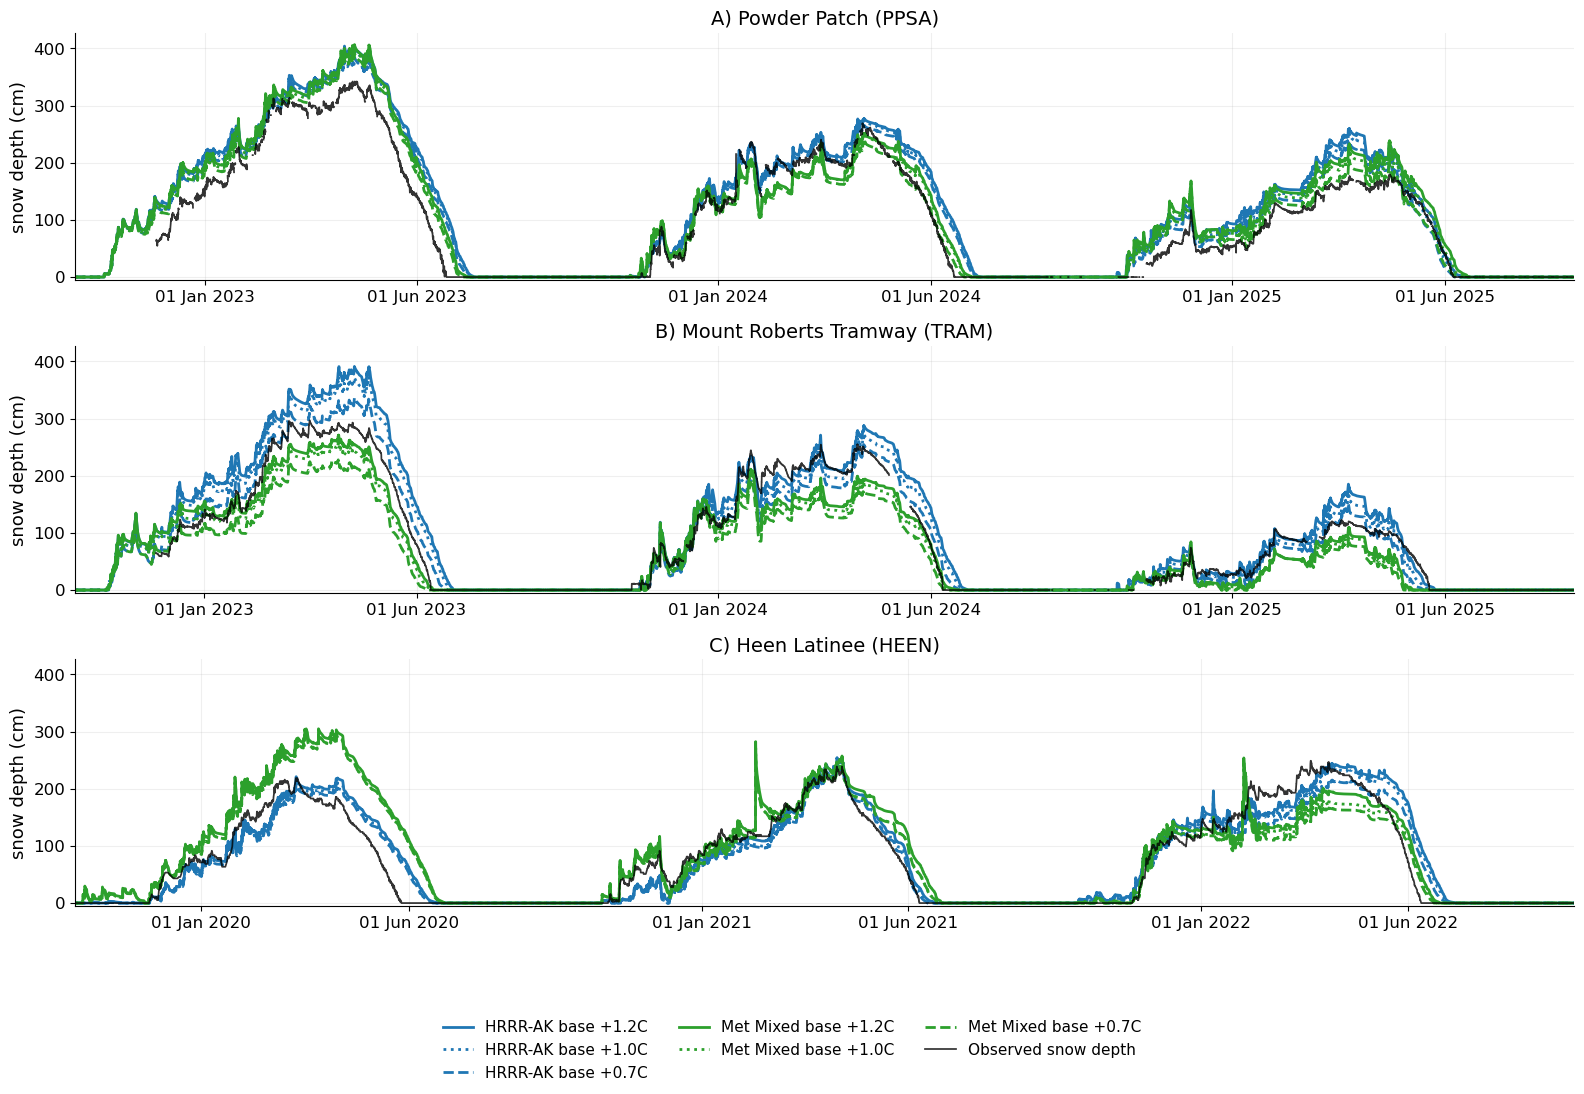

In [3]:
fig,axes=plt.subplots(3,1,figsize=(16,11),sharey=MATCH_Y_AXES)
for letter,(site,years),ax in zip('ABC',ANALYSIS_YEARS.items(),axes):
    start,end=plot_windows[site]
    for (forcing,experiment),style in SIMULATION_STYLES.items():
        frame=pairs[(site,forcing)]
        ax.plot(frame.index,frame[f'HS_cm_{experiment}'],**style)
    obs=observations[site].loc[start:end]
    ax.plot(obs.index,obs,**OBSERVATION_STYLE,label='Observed snow depth',zorder=5)
    ax.set(title=f'{letter}) {SITE_TITLES[site]}',ylabel='snow depth (cm)',xlabel='',xlim=(start,end))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,6],bymonthday=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
    ax.tick_params(axis='y',labelleft=True)
    ax.grid(alpha=.2)
    ax.set_ylim(bottom=-5)
handles=[Line2D([],[],**style) for style in SIMULATION_STYLES.values()]
handles.append(Line2D([],[],**OBSERVATION_STYLE,label='Observed snow depth'))
fig.tight_layout(rect=(0,.13,1,1))
fig.legend(handles=handles,loc='lower center',ncol=3,frameon=False)
plt.show()

## Threshold response: depth and reported snowfall

Differences are each sensitivity (+1.0°C or +0.7°C) minus the +1.2°C base control. Daily mean depth differences and cumulative model-reported snowfall differences share the selected windows; cumulative differences restart at each window’s start. Hourly `MS_Snow` and `MS_Rain` fluxes (kg m⁻² h⁻¹) integrate over one-hour records to mm. Original total-precipitation forcing files remain unchanged.

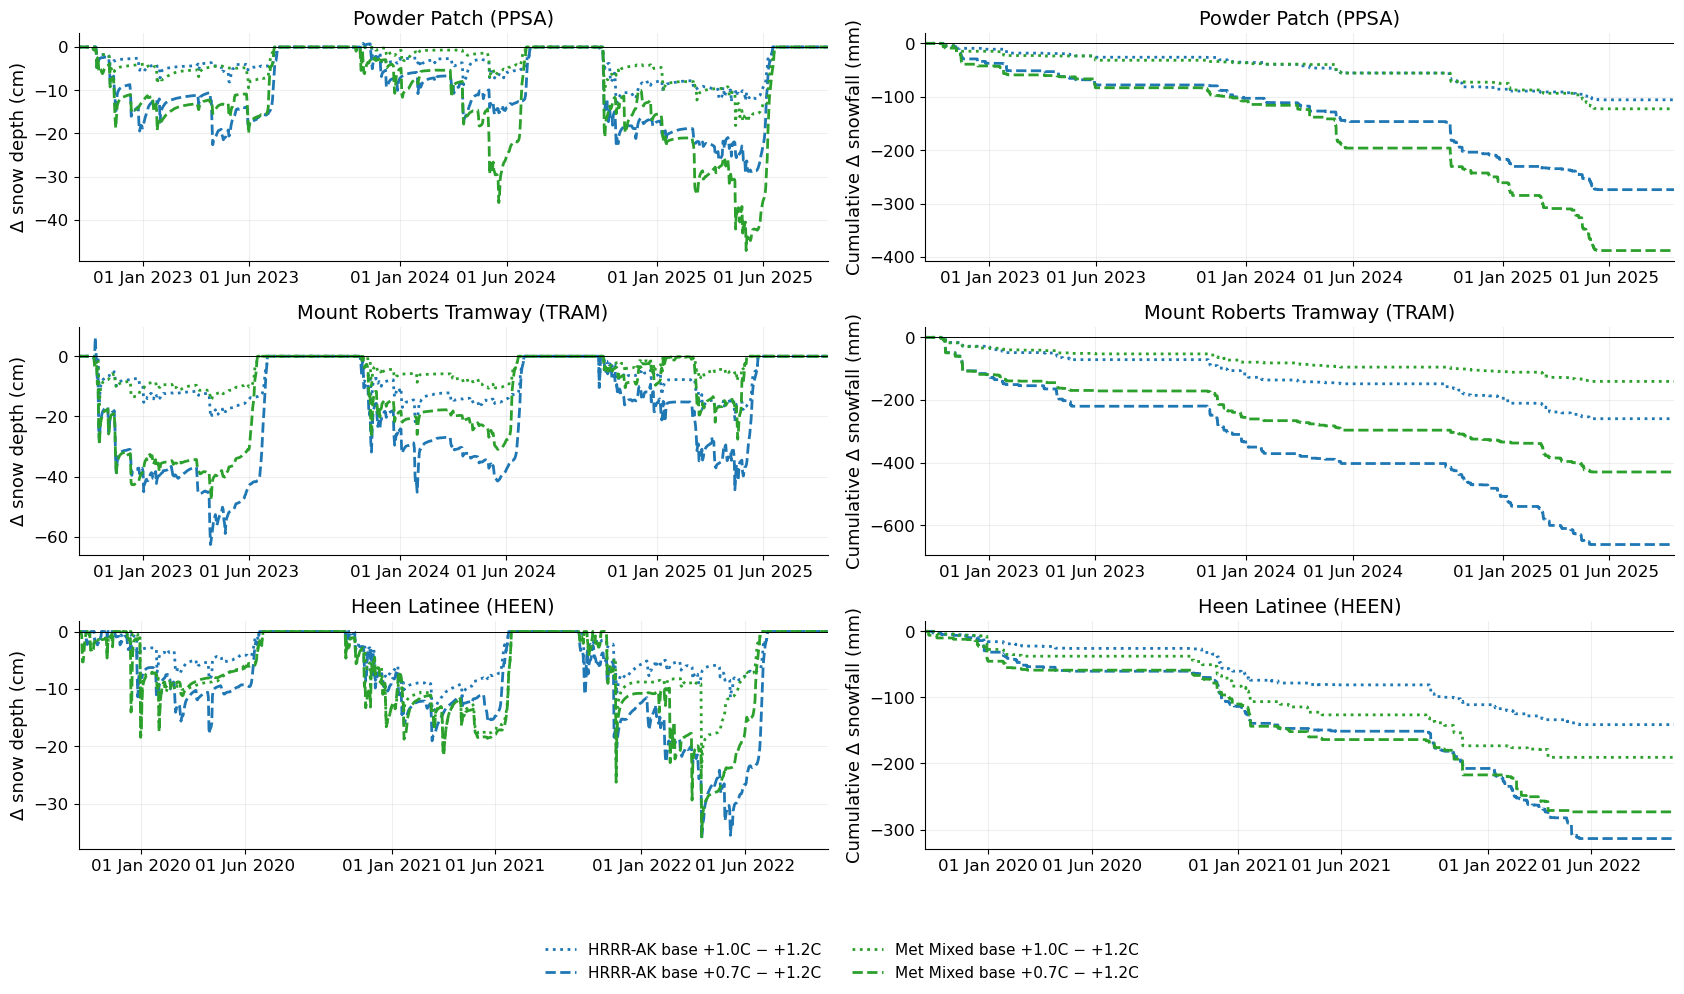

In [4]:
fig,axes=plt.subplots(3,2,figsize=(17,10))
for i,site in enumerate(ANALYSIS_YEARS):
    for forcing in sensitivity.FORCINGS:
        frame=pairs[(site,forcing)]
        for experiment in CANDIDATES:
            style=dict(SIMULATION_STYLES[(forcing,experiment)])
            style['label'] += ' − +1.2C'
            delta=frame[f'delta_HS_cm_{experiment}'].resample('D').mean()
            axes[i,0].plot(delta.index,delta,**style)
            axes[i,1].plot(frame.index,frame[f'delta_snowfall_mm_{experiment}'].cumsum(),**style)
    axes[i,0].set(title=SITE_TITLES[site],ylabel='Δ snow depth (cm)')
    axes[i,1].set(title=SITE_TITLES[site],ylabel='Cumulative Δ snowfall (mm)')
    for ax in axes[i]:
        ax.axhline(0,color='black',lw=.7);ax.grid(alpha=.2)
        ax.set_xlim(plot_windows[site])
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,6],bymonthday=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
fig.tight_layout(rect=(0,.10,1,1))
handles=[Line2D([],[],**{**SIMULATION_STYLES[(f,e)],
    'label':SIMULATION_STYLES[(f,e)]['label']+' − +1.2C'}) for f in sensitivity.FORCINGS for e in CANDIDATES]
fig.legend(handles=handles,loc='lower center',ncol=2,frameon=False)
plt.show()

## Seasonal statistics

The melt-out calculation reuses the established step-5 rule: modeled snow depth ≤1 cm and SWE ≤1 mm for seven consecutive days, at least 18 valid hours/day, sufficient March–August coverage, and a substantial seasonal snowpack. The status columns distinguish a confirmed date from insufficient coverage or an unconfirmed disappearance. Positive melt shifts mean later disappearance at the candidate threshold; negative shifts mean earlier disappearance.

Observation MAE/RMSE/bias use only the common valid hourly observations. Negative MAE changes mean improved modeled depth agreement. Partial water years and first seasons remain flagged and are not silently treated as complete independent seasons.

Only the three selected water years per site enter these statistics. Initialization-sensitive flags retain the original run start: PPSA/TRAM HRRR-only WY2023 is not mislabeled as an initial model season.

In [5]:
columns=['site','forcing','threshold','water_year','initialization_sensitive','complete_water_year','paired_hours','obs_hours',
    'mean_absolute_delta_HS_cm','peak_HS_base_cm','peak_HS_candidate_cm','peak_HS_change_cm',
    'peak_SWE_change_mm','reported_snowfall_change_mm','melt_base','melt_candidate',
    'melt_shift_days','melt_base_status','melt_candidate_status','MAE_base_cm','MAE_candidate_cm','MAE_change_cm',
    'RMSE_base_cm','RMSE_candidate_cm','RMSE_change_cm']
seasonal_display=metrics[columns].round(2).copy()
seasonal_display['forcing']=seasonal_display.forcing.map(FORCING_LABELS)
for column in ['melt_base','melt_candidate']:
    seasonal_display[column]=pd.to_datetime(seasonal_display[column]).dt.strftime('%d %b %Y').fillna('Not confirmed')
display(seasonal_display)
# A season-level summary avoids giving longer model runs extra weight.
summary=metrics.groupby(['site','forcing','threshold'],sort=False).agg(
    seasons=('water_year','count'),obs_hours=('obs_hours','sum'),
    mean_absolute_depth_change_cm=('mean_absolute_delta_HS_cm','mean'),
    mean_peak_depth_change_cm=('peak_HS_change_cm','mean'),
    mean_reported_snowfall_change_mm=('reported_snowfall_change_mm','mean'),
    mean_melt_shift_days=('melt_shift_days','mean'),confirmed_melt_pairs=('melt_shift_days','count'),
    mean_MAE_change_cm=('MAE_change_cm','mean'),
    mean_RMSE_change_cm=('RMSE_change_cm','mean'))
display(summary.rename(index=FORCING_LABELS,level='forcing').round(2))

# Direct three-threshold comparison on the same site/forcing/seasons.
keys=['site','forcing','water_year']
control=metrics.drop_duplicates(keys)[keys+['RMSE_base_cm','MAE_base_cm','peak_HS_base_cm','melt_base']].copy()
control=control.rename(columns={'RMSE_base_cm':'RMSE_cm','MAE_base_cm':'MAE_cm','peak_HS_base_cm':'peak_HS_cm','melt_base':'melt_out'})
control['threshold']='1.2°C'
candidates=metrics[keys+['threshold','RMSE_candidate_cm','MAE_candidate_cm','peak_HS_candidate_cm','melt_candidate']].rename(
    columns={'RMSE_candidate_cm':'RMSE_cm','MAE_candidate_cm':'MAE_cm','peak_HS_candidate_cm':'peak_HS_cm','melt_candidate':'melt_out'})
three_threshold_metrics=pd.concat([control,candidates],ignore_index=True)
display(three_threshold_metrics.pivot(index=keys,columns='threshold',values=['RMSE_cm','MAE_cm','peak_HS_cm','melt_out']))

,site,forcing,threshold,water_year,initialization_sensitive,complete_water_year,paired_hours,obs_hours,mean_absolute_delta_HS_cm,peak_HS_base_cm,...,melt_candidate,melt_shift_days,melt_base_status,melt_candidate_status,MAE_base_cm,MAE_candidate_cm,MAE_change_cm,RMSE_base_cm,RMSE_candidate_cm,RMSE_change_cm
0,ppsa,HRRR-AK,1.0°C,2023,False,True,8760,5132,2.89,404.35,...,11 Jul 2023,-1,confirmed,confirmed,51.42,47.56,-3.86,58.30,54.46,-3.85
1,ppsa,HRRR-AK,1.0°C,2024,False,True,8784,6830,2.38,277.32,...,04 Jul 2024,-1,confirmed,confirmed,21.11,18.75,-2.36,31.91,28.91,-2.99
2,ppsa,HRRR-AK,1.0°C,2025,False,False,8041,7234,6.57,260.23,...,10 Jun 2025,-5,confirmed,confirmed,30.05,23.76,-6.28,39.34,32.34,-7.00
3,ppsa,Met Mixed,1.0°C,2023,False,True,8760,5132,3.52,406.72,...,06 Jul 2023,-1,confirmed,confirmed,43.81,39.04,-4.78,48.88,44.07,-4.81
4,ppsa,Met Mixed,1.0°C,2024,False,True,8784,6830,1.22,251.48,...,29 Jun 2024,-1,confirmed,confirmed,15.39,14.58,-0.80,20.70,19.86,-0.84
5,ppsa,Met Mixed,1.0°C,2025,False,False,8041,7234,6.37,238.64,...,17 Jun 2025,-1,confirmed,confirmed,26.50,19.89,-6.62,32.29,25.53,-6.75
6,tram,HRRR-AK,1.0°C,2023,False,False,8754,7373,8.12,391.10,...,27 Jun 2023,-1,confirmed,confirmed,44.32,35.39,-8.93,55.71,44.76,-10.95
7,tram,HRRR-AK,1.0°C,2024,False,True,8784,7342,8.01,287.65,...,23 Jun 2024,-4,confirmed,confirmed,16.81,14.81,-2.00,25.85,21.63,-4.21
8,tram,HRRR-AK,1.0°C,2025,False,False,8041,7151,6.41,185.28,...,23 May 2025,-2,confirmed,confirmed,11.57,9.38,-2.19,18.91,14.30,-4.61
9,tram,Met Mixed,1.0°C,2023,True,False,8754,7373,6.30,271.23,...,12 Jun 2023,-1,confirmed,confirmed,17.38,20.66,3.28,23.76,28.92,5.15


seasons  obs_hours  mean_absolute_depth_change_cm  \
site forcing   threshold                                                      
ppsa HRRR-AK   1.0°C            3      19196                           3.95   
     Met Mixed 1.0°C            3      19196                           3.70   
tram HRRR-AK   1.0°C            3      21866                           7.52   
     Met Mixed 1.0°C            3      21866                           4.07   
heen HRRR-AK   1.0°C            3      23458                           3.88   
     Met Mixed 1.0°C            3      23458                           6.05   
ppsa HRRR-AK   0.7°C            3      19196                           9.82   
     Met Mixed 0.7°C            3      19196                          11.14   
tram HRRR-AK   0.7°C            3      21866                          19.06   
     Met Mixed 0.7°C            3      21866                          12.49   
heen HRRR-AK   0.7°C            3      23458                           8.40   
     Met Mixed 0.7°C            3      23458                           7.65   

                          mean_peak_depth_change_cm  \
site forcing   threshold                              
ppsa HRRR-AK   1.0°C                          -5.89   
     Met Mixed 1.0°C                          -5.47   
tram HRRR-AK   1.0°C                         -16.19   
     Met Mixed 1.0°C                          -7.93   
heen HRRR-AK   1.0°C                          -6.94   
     Met Mixed 1.0°C                          -9.51   
ppsa HRRR-AK   0.7°C                         -18.77   
     Met Mixed 0.7°C                         -19.69   
tram HRRR-AK   0.7°C                         -41.04   
     Met Mixed 0.7°C                         -26.79   
heen HRRR-AK   0.7°C                         -17.15   
     Met Mixed 0.7°C                         -10.13   

                          mean_reported_snowfall_change_mm  \
site forcing   threshold                                     
ppsa HRRR-AK   1.0°C                                -35.23   
     Met Mixed 1.0°C                                -40.84   
tram HRRR-AK   1.0°C                                -86.53   
     Met Mixed 1.0°C                                -46.88   
heen HRRR-AK   1.0°C                                -47.06   
     Met Mixed 1.0°C                                -63.57   
ppsa HRRR-AK   0.7°C                                -91.27   
     Met Mixed 0.7°C                               -129.26   
tram HRRR-AK   0.7°C                               -220.37   
     Met Mixed 0.7°C                               -143.19   
heen HRRR-AK   0.7°C                               -104.54   
     Met Mixed 0.7°C                                -91.07   

                          mean_melt_shift_days  confirmed_melt_pairs  \
site forcing   threshold                                               
ppsa HRRR-AK   1.0°C                     -2.33                     3   
     Met Mixed 1.0°C                     -1.00                     3   
tram HRRR-AK   1.0°C                     -2.33                     3   
     Met Mixed 1.0°C                     -2.33                     3   
heen HRRR-AK   1.0°C                     -3.00                     3   
     Met Mixed 1.0°C                     -2.00                     3   
ppsa HRRR-AK   0.7°C                     -4.00                     3   
     Met Mixed 0.7°C                     -5.67                     3   
tram HRRR-AK   0.7°C                     -6.33                     3   
     Met Mixed 0.7°C                     -4.33                     3   
heen HRRR-AK   0.7°C                     -4.67                     3   
     Met Mixed 0.7°C                     -3.00                     3   

                          mean_MAE_change_cm  mean_RMSE_change_cm  
site forcing   threshold                                           
ppsa HRRR-AK   1.0°C                   -4.17                -4.61  
     Met Mixed 1.0°C                   -4.06                -4.13 

RMSE_cm                        \
threshold                                 0.7°C      1.0°C      1.2°C   
site forcing              water_year                                    
heen hrrrak_lapserate     2020        23.548297  24.655262  26.114069   
                          2021        16.760578  16.232127  15.603456   
                          2022        26.799253  27.636285   29.60287   
     met_hrrrak_lapserate 2020        57.888294  57.798449  62.953497   
                          2021        20.021336  20.371699  26.373593   
                          2022        38.484882  33.826081  28.996424   
ppsa hrrrak_lapserate     2023        45.273296  54.456449  58.302413   
                          2024        25.036429  28.914909  31.905452   
                          2025        24.967237  32.342227  39.340013   
     met_hrrrak_lapserate 2023        36.820869   44.07248  48.881113   
                          2024        20.340856  19.858997  20.701625   
                          2025        16.643953  25.533815  32.286478   
tram hrrrak_lapserate     2023        21.564991   44.76154  55.710902   
                          2024        21.993518  21.634508  25.848269   
                          2025         14.71151  14.296726  18.908089   
     met_hrrrak_lapserate 2023         44.97769  28.919296  23.764699   
                          2024         45.47138   37.03778  33.056769   
                          2025        29.373123  25.655479  23.821319   

                                         MAE_cm                        \
threshold                                 0.7°C      1.0°C      1.2°C   
site forcing              water_year                                    
heen hrrrak_lapserate     2020        14.209974  14.783257  15.557944   
                          2021        10.990546  10.863423  10.369177   
                          2022        17.066403  17.786534   19.30409   
     met_hrrrak_lapserate 2020        39.010793  39.064831  43.201473   
                          2021        12.092269  12.275312  15.673628   
                          2022        23.986856  21.345633  18.605199   
ppsa hrrrak_lapserate     2023        38.714272  47.557536  51.421496   
                          2024        15.910654  18.746559  21.106293   
                          2025        18.705889  23.762486  30.045654   
     met_hrrrak_lapserate 2023        31.796762   39.03507  43.810108   
                          2024        13.642512  14.583801  15.386044   
                          2025        11.930261  19.886934  26.502243   
tram hrrrak_lapserate     2023        15.834462  35.394856  44.321623   
                          2024        14.743122  14.810163  16.811961   
                          2025         9.610368    9.37997  11.567623   
     met_hrrrak_lapserate 2023        32.251604  20.659331  17.382052   
                          2024        31.290762  24.410646  21.674497   
                          2025        20.367529  17.892925  16.702818   

                                     peak_HS_cm                     melt_out  \
threshold                                 0.7°C    1.0°C    1.2°C      0.7°C   
site forcing              water_year                                           
heen hrrrak_lapserate     2020           209.63  215.773  221.103 2020-06-19   
                          2021          242.562  244.736  254.023 2021-06-15   
                          2022          215.909   238.25  244.439 2022-06-30   
     met_hrrrak_lapserate 2020          296.493  295.762  304.877 2020-06-25   
                          2021          270.667  271.672  282.406 2021-06-22   
                          2022          243.637  245.238  253.905 2022-06-20   
ppsa hrrrak_lapserate     2023          384.757  399.965  404.349 2023-07-09   
                          2024          265.361  273.916  277.318 2024-07-03   
                          2025           235.46   250.34  260.226 2025-06-08   
     met_hrr

## Running and provenance

Each model site has `base_thresh07_runs.json` and `base_thresh10_runs.json`, with matching config and output experiment names. The +1.2°C control retains its original name `base`. Source forcing, initial profiles, base controls, and their checksums are preserved. Existing candidate products are protected against overwriting.

For a fresh +1.0°C setup, from the repository root in the JIF environment:

```bash
python sites/all_sites/_base_threshold_sensitivity.py prepare --experiment base_thresh10
python sites/all_sites/_base_threshold_sensitivity.py run --experiment base_thresh10 --workers 6 --empty-column-guard-sites tram
```

Use `--experiment base_thresh07` for +0.7°C. The notebook reads all twelve sensitivity status records. Figures and tables display inline. Optional diagnostics belong in ignored `temporary/base_thresh10/` or `temporary/base_thresh07/`.

### TRAM numerical workaround

The +0.7°C TRAM runs initially crashed in SNOWPACK 3.7.0 vapor transport. They were rerun with `numerics/empty_snow_vapour_guard.gdb`, reused from the radar-site workflow and checked against the installed library SHA-256. It returns from layer-to-layer vapor transport only after surface sublimation has left an empty column. Surface sublimation and all calls with remaining layers are retained. No input or physical parameter is changed. The +1.0°C TRAM runs also use this guard from the start. The status records identify guarded runs and count guard applications. The +0.7°C retries matched every pre-crash snow-depth, SWE, snowfall, and rainfall output. This version-specific workaround is not validation against a future upstream fix; retain its provenance when interpreting or publishing these results.

In [6]:
status=[]
for row in manifest:
    path=Path(row['output']).with_suffix('.status.json')
    status.append({**json.loads(path.read_text()),'experiment':row['experiment']})
status_display=pd.DataFrame(status)
status_display['numerical_guard']=status_display.get('numerical_guard',pd.Series(index=status_display.index,dtype='object')).fillna('None')
status_display['empty_column_guard_count']=status_display.get('empty_column_guard_count',pd.Series(0,index=status_display.index)).fillna(0).astype(int)
status_display['forcing']=status_display.forcing.map(FORCING_LABELS)
display(status_display[['site','forcing','experiment','returncode','finished','complete','rows',
    'inputs_preserved','control_preserved','numerical_guard','empty_column_guard_count']])

,site,forcing,experiment,returncode,finished,complete,rows,inputs_preserved,control_preserved,numerical_guard,empty_column_guard_count
0,ppsa,HRRR-AK,base_thresh10,0,True,True,51883,True,True,None,0
1,ppsa,Met Mixed,base_thresh10,0,True,True,51883,True,True,None,0
2,tram,HRRR-AK,base_thresh10,0,True,True,51883,True,True,/home/cassie/python/repos/snow_modeling_point/...,0
3,tram,Met Mixed,base_thresh10,0,True,True,25579,True,True,/home/cassie/python/repos/snow_modeling_point/...,0
4,heen,HRRR-AK,base_thresh10,0,True,True,51883,True,True,None,0
5,heen,Met Mixed,base_thresh10,0,True,True,26280,True,True,None,0
6,ppsa,HRRR-AK,base_thresh07,0,True,True,51883,True,True,None,0
7,ppsa,Met Mixed,base_thresh07,0,True,True,51883,True,True,None,0
8,tram,HRRR-AK,base_thresh07,0,True,True,51883,True,True,/home/cassie/python/repos/snow_modeling_point/...,1
9,tram,Met Mixed,base_thresh07,0,True,True,25579,True,True,/home/cassie/python/repos/snow_modeling_point/...,2


## Concise performance summary

Each sensitivity is compared with +1.2°C on the same 18 forcing-seasons. Negative RMSE changes mean better agreement with observed depth; negative melt shifts mean earlier disappearance. Partial-year and initialization flags remain visible above. The control is counted once in the direct three-threshold table.

In [7]:
performance_summary=metrics.groupby(['threshold','site'],sort=False).agg(
    forcing_seasons=('water_year','count'),
    observed_seasons=('RMSE_change_cm','count'),
    improved_RMSE=('RMSE_change_cm',lambda x:int(x.lt(0).sum())),
    median_RMSE_change_cm=('RMSE_change_cm','median'),
    confirmed_melt_pairs=('melt_shift_days','count'),
    median_melt_shift_days=('melt_shift_days','median'),
    median_peak_depth_change_cm=('peak_HS_change_cm','median'))
display(performance_summary.round(2))
lines=[]
for experiment in CANDIDATES:
    use=metrics.loc[metrics.experiment.eq(experiment)]
    error=use.dropna(subset=['RMSE_change_cm'])
    lines.append(f"- **{THRESHOLD_LABELS[experiment]} vs 1.2°C:** lower RMSE in "
        f"**{int(error.RMSE_change_cm.lt(0).sum())}/{len(error)} forcing-seasons**; "
        f"median RMSE change **{error.RMSE_change_cm.median():+.1f} cm**; "
        f"median melt-out shift **{use.melt_shift_days.median():+.1f} days**.")
display(Markdown('\n'.join(lines)))

forcing_seasons  observed_seasons  improved_RMSE  \
threshold site                                                     
1.0°C     ppsa                6                 6              6   
          tram                6                 6              3   
          heen                6                 6              4   
0.7°C     ppsa                6                 6              6   
          tram                6                 6              3   
          heen                6                 6              4   

                median_RMSE_change_cm  confirmed_melt_pairs  \
threshold site                                                
1.0°C     ppsa                  -4.33                     6   
          tram                  -1.19                     6   
          heen                  -1.71                     6   
0.7°C     ppsa                 -12.54                     6   
          tram                   0.85                     6   
          heen                  -2.68                     6   

                median_melt_shift_days  median_peak_depth_change_cm  
threshold site                                                       
1.0°C     ppsa                    -1.0                        -4.41  
          tram                    -1.5                       -14.08  
          heen                    -2.5                        -8.89  
0.7°C     ppsa                    -4.0                       -17.17  
          tram                    -5.5                       -34.04  
          heen                    -3.5                       -11.47

- **1.0°C vs 1.2°C:** lower RMSE in **13/18 forcing-seasons**; median RMSE change **-3.4 cm**; median melt-out shift **-1.5 days**.
- **0.7°C vs 1.2°C:** lower RMSE in **13/18 forcing-seasons**; median RMSE change **-4.0 cm**; median melt-out shift **-4.5 days**.